# Exploring bean-leaf images

This notebook prepares for a **three-class image classifier**: angular leaf spot, bean rust, and healthy leaves. These labels describe leaf health, not different plant species. We will examine the training images, but not train a model.

**Split policy:** We count labels in all three original splits, but decode, visualize and calculate image statistics only for the training split. Keep validation for model development and test for final evaluation.

## 1. Load and validate the data

Run this notebook from anywhere inside the repository with a Python environment containing `numpy`, `pandas`, `matplotlib`, `Pillow`, and Jupyter. The notebook searches parent directories for Session 2's `src/data/beans128.npz`. If the file is elsewhere, set the `BEANS_DATASET_PATH` environment variable to its full path before starting Jupyter.

The NPZ stores JPEG files concatenated as bytes; `offsets` identifies each JPEG. `labels` and `split` identify the class and original split of each image. See the [dataset README](../../../session2_inside_the_black_box/src/data/README.md) for provenance, format, and licensing considerations.

In [2]:
import io
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, UnidentifiedImageError
from IPython.display import display

CLASS_NAMES = ('angular_leaf_spot', 'bean_rust', 'healthy')
SPLIT_NAMES = ('train', 'validation', 'test')
SEED = 42
relative_dataset = Path('session2_inside_the_black_box/src/data/beans128.npz')
configured_path = os.environ.get('BEANS_DATASET_PATH')
if configured_path:
    dataset_path = Path(configured_path).expanduser().resolve()
else:
    dataset_path = next(
        (parent / relative_dataset for parent in (Path.cwd(), *Path.cwd().parents)
         if (parent / relative_dataset).is_file()),
        None,
    )
if dataset_path is None or not dataset_path.is_file():
    raise FileNotFoundError(
        'Cannot find beans128.npz. Start Jupyter inside the repository or set '
        'BEANS_DATASET_PATH to the dataset file.'
    )
print(f'Dataset: {dataset_path}')

Dataset: /mnt/c/Users/edgar/Source/AI-Workshop-UNTRM/session2_inside_the_black_box/src/data/beans128.npz


In [3]:
with np.load(dataset_path, allow_pickle=False) as pack:
    jpeg = pack['jpeg']
    offsets = pack['offsets']
    labels = pack['labels']
    splits = pack['split']

for name, array in [('jpeg', jpeg), ('offsets', offsets), ('labels', labels), ('split', splits)]:
    print(f'{name:8} shape={array.shape}, dtype={array.dtype}')

if jpeg.ndim != 1 or jpeg.dtype != np.uint8:
    raise ValueError('jpeg must be a one-dimensional uint8 byte array.')
if any(array.ndim != 1 or not np.issubdtype(array.dtype, np.integer)
       for array in (offsets, labels, splits)):
    raise ValueError('offsets, labels and split must be one-dimensional integer arrays.')
if len(labels) == 0 or len(splits) != len(labels) or len(offsets) != len(labels) + 1:
    raise ValueError('The labels, split and offsets arrays have inconsistent lengths.')
if offsets[0] != 0 or offsets[-1] != len(jpeg) or np.any(offsets[1:] <= offsets[:-1]):
    raise ValueError('JPEG offsets must be strictly increasing and span the byte array.')
if not np.isin(labels, range(len(CLASS_NAMES))).all():
    raise ValueError('The dataset contains an unknown class label.')
if not np.isin(splits, range(len(SPLIT_NAMES))).all():
    raise ValueError('The dataset contains an unknown split value.')
if not all(np.any((splits == 0) & (labels == class_id)) for class_id in range(len(CLASS_NAMES))):
    raise ValueError('Each class must have at least one training image.')

jpeg     shape=(10630842,), dtype=uint8
offsets  shape=(1296,), dtype=int64
labels   shape=(1295,), dtype=int64
split    shape=(1295,), dtype=int64


## 2. Class balance and original splits

Counts and percentages use label metadata only, including for validation and test. Compare the classes within each split: a heavily imbalanced dataset may make accuracy misleading. Uniform random guessing among three classes gives about 33% expected accuracy.

Class counts and total images by split:


,angular_leaf_spot,bean_rust,healthy,total
split,,,,
train,345,348,341,1034
validation,44,45,44,133
test,43,43,42,128


Percent of each split:


,angular_leaf_spot,bean_rust,healthy
split,,,
train,33.4,33.7,33.0
validation,33.1,33.8,33.1
test,33.6,33.6,32.8


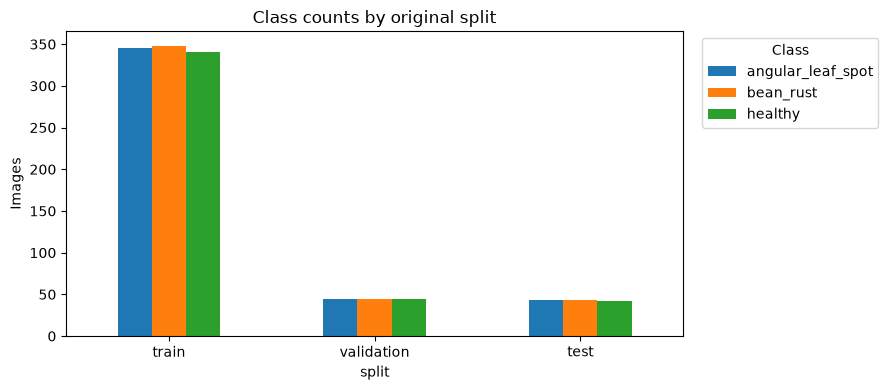

In [4]:
counts = pd.DataFrame(
    [[np.count_nonzero((splits == split_id) & (labels == class_id))
      for class_id in range(len(CLASS_NAMES))] for split_id in range(len(SPLIT_NAMES))],
    index=pd.Index(SPLIT_NAMES, name='split'),
    columns=CLASS_NAMES,
)
totals = counts.sum(axis=1)
print('Class counts and total images by split:')
display(counts.assign(total=totals))
print('Percent of each split:')
display(counts.div(totals.replace(0, np.nan), axis=0).mul(100).round(1))
ax = counts.plot.bar(rot=0, figsize=(9, 4), ylabel='Images', title='Class counts by original split')
ax.legend(title='Class', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 3. Decode and inspect the training images

Only training JPEGs are decoded below. We check the decoded dimensions and original color modes before converting to RGB. A corrupt or unexpectedly sized training image stops the notebook with its dataset index instead of being silently omitted.

In [5]:
train_indices = np.flatnonzero(splits == 0)
train_labels = labels[train_indices]
train_images = []
image_metadata = []
for index in train_indices:
    image_bytes = jpeg[offsets[index]:offsets[index + 1]].tobytes()
    try:
        with Image.open(io.BytesIO(image_bytes)) as image:
            image.load()
            image_metadata.append((image.width, image.height, image.mode))
            rgb = np.asarray(image.convert('RGB'))
    except (OSError, ValueError, UnidentifiedImageError) as exc:
        raise ValueError(f'Could not decode training image at dataset index {index}.') from exc
    if rgb.shape != (128, 128, 3):
        raise ValueError(f'Training image at dataset index {index} has unexpected RGB shape {rgb.shape}.')
    train_images.append(rgb)
train_images = np.stack(train_images)
metadata = pd.DataFrame(image_metadata, columns=['width', 'height', 'original_mode'])
print(f'Decoded training array: {train_images.shape}, dtype={train_images.dtype}')
print('Training image dimensions and original color modes:')
display(metadata.value_counts().rename('images').to_frame())

Decoded training array: (1034, 128, 128, 3), dtype=uint8
Training image dimensions and original color modes:


,,,images
width,height,original_mode,
128,128,RGB,1034


### Example leaves

A fixed random seed makes this sample reproducible. Compare lesions and leaf appearance, but also notice lighting, shadows, background, and how much of the frame the leaf occupies. A small sample cannot establish how common any feature is.

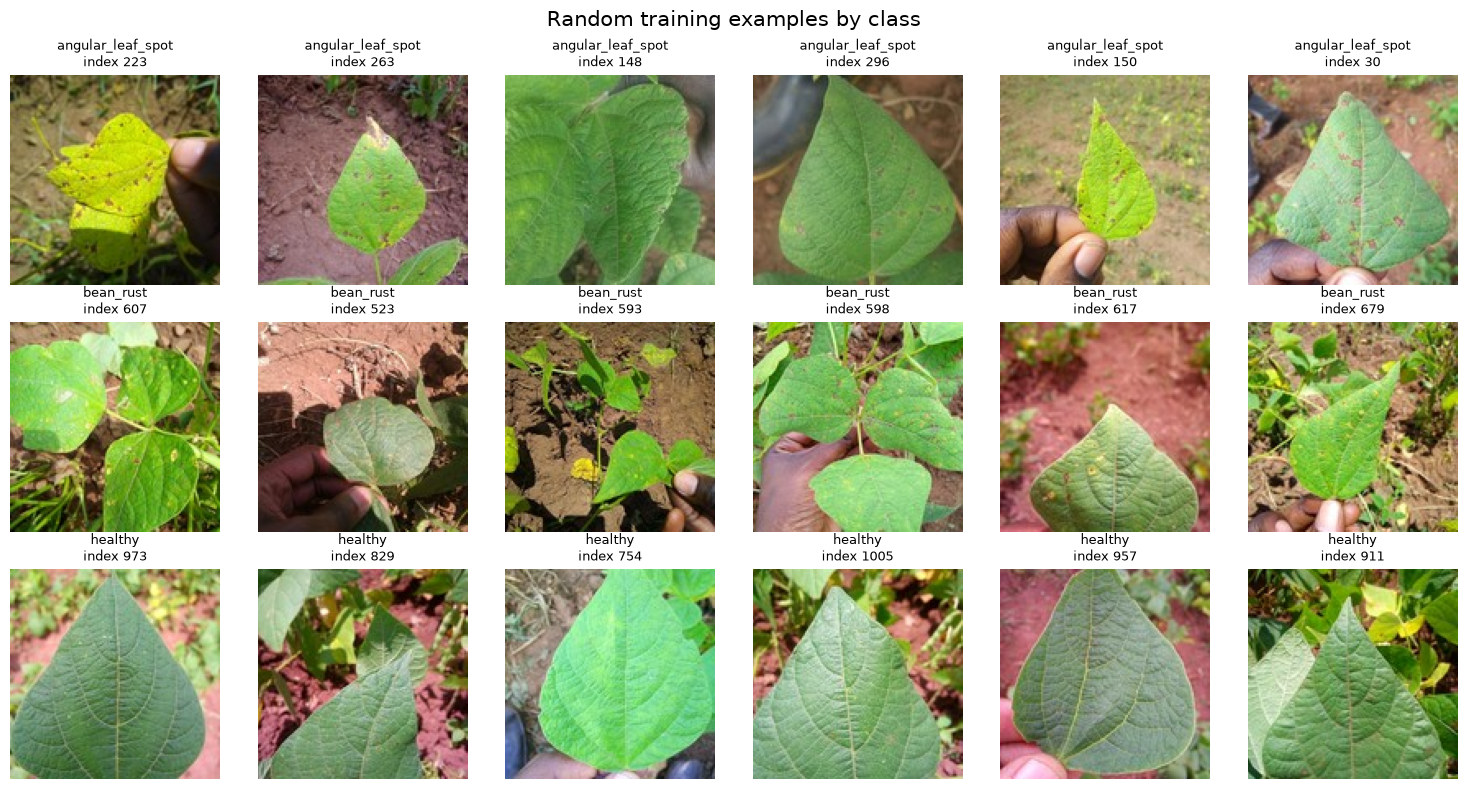

In [6]:
rng = np.random.default_rng(SEED)
samples_per_class = 6
fig, axes = plt.subplots(len(CLASS_NAMES), samples_per_class, figsize=(15, 8), squeeze=False)
for class_id, class_name in enumerate(CLASS_NAMES):
    positions = np.flatnonzero(train_labels == class_id)
    selected = rng.choice(positions, size=min(samples_per_class, len(positions)), replace=False)
    for ax in axes[class_id]:
        ax.axis('off')
    for ax, position in zip(axes[class_id], selected):
        ax.imshow(train_images[position])
        ax.set_title(f'{class_name}\nindex {train_indices[position]}', fontsize=9)
fig.suptitle('Random training examples by class', fontsize=15)
plt.tight_layout()
plt.show()

## 4. Color and brightness

For each training image, calculate the average red, green and blue values on the 0–255 scale. Brightness here is an approximate luminance: `0.2126 × red + 0.7152 × green + 0.0722 × blue`. These are whole-image statistics, **not leaf-only measurements**; backgrounds and lighting can dominate them. Differences between classes are hypotheses to investigate, not proof of a disease signature.

Training per-image mean and standard deviation by class (0–255):


red        green        blue       brightness      
                    mean   std   mean   std  mean   std       mean   std
class                                                                   
angular_leaf_spot  129.0  25.6  134.8  21.7  74.1  24.0      129.2  20.2
bean_rust          120.7  27.9  119.4  21.3  78.4  26.9      116.8  21.3
healthy            121.2  21.6  142.6  21.4  86.7  24.9      134.0  18.9

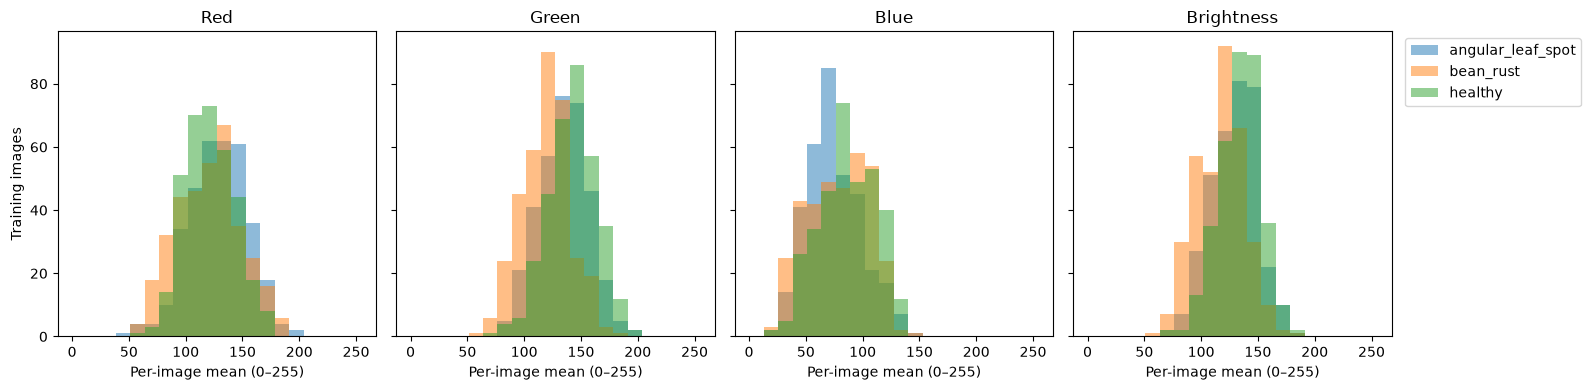

In [7]:
channel_means = train_images.mean(axis=(1, 2))
brightness = channel_means @ np.array([0.2126, 0.7152, 0.0722])
statistics = pd.DataFrame(channel_means, columns=['red', 'green', 'blue'])
statistics['brightness'] = brightness
statistics['class'] = [CLASS_NAMES[label] for label in train_labels]
print('Training per-image mean and standard deviation by class (0–255):')
display(statistics.groupby('class')[['red', 'green', 'blue', 'brightness']].agg(['mean', 'std']).round(1))

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, column in zip(axes, ['red', 'green', 'blue', 'brightness']):
    for class_name in CLASS_NAMES:
        values = statistics.loc[statistics['class'] == class_name, column]
        ax.hist(values, bins=np.linspace(0, 255, 21), alpha=0.5, label=class_name)
    ax.set(title=column.capitalize(), xlabel='Per-image mean (0–255)')
axes[0].set_ylabel('Training images')
axes[-1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Brightness extremes

These training images have the lowest and highest whole-image average brightness in each class. Inspect whether shadows, exposure or backgrounds explain the extremes; they are not automatically errors or mislabeled examples.

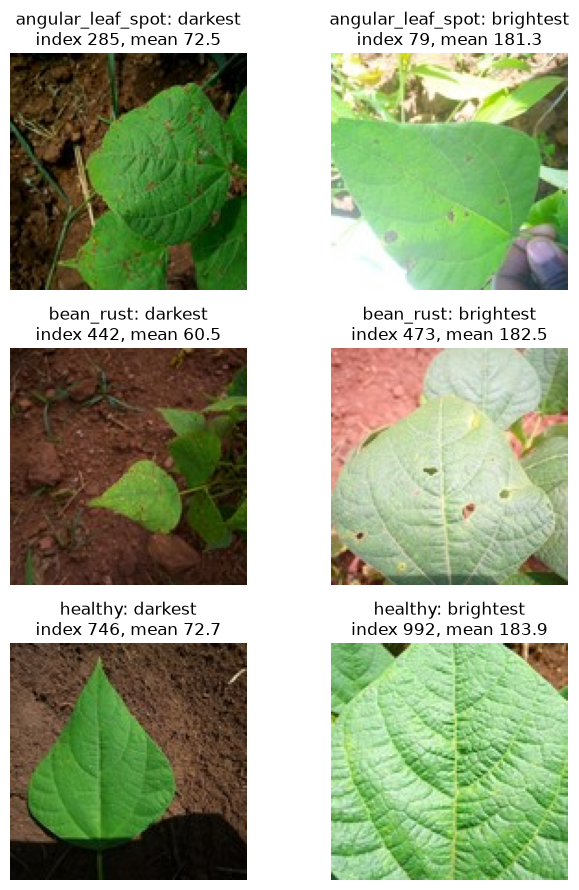

In [8]:
fig, axes = plt.subplots(len(CLASS_NAMES), 2, figsize=(7, 9), squeeze=False)
for class_id, class_name in enumerate(CLASS_NAMES):
    positions = np.flatnonzero(train_labels == class_id)
    for ax, position, description in zip(
        axes[class_id],
        (positions[np.argmin(brightness[positions])], positions[np.argmax(brightness[positions])]),
        ('darkest', 'brightest'),
    ):
        ax.imshow(train_images[position])
        ax.set_title(f'{class_name}: {description}\nindex {train_indices[position]}, mean {brightness[position]:.1f}')
        ax.axis('off')
plt.tight_layout()
plt.show()

## 5. Takeaways and next steps

The next cell reports facts computed from this run. Review the image grids and distributions above before drawing conclusions about visual quality or class differences.

- **Potential shortcuts:** A model could learn background or lighting rather than leaf disease. Check difficult cases and test performance on new photographs from other settings.
- **Resolution and labels:** Images have been resized to 128×128; small lesions may be harder to see. Labels may contain uncertainty, which these plots alone cannot resolve.
- **Preprocessing:** Try scaling and normalization appropriate to the model. Compare modest training-only augmentation (for example flips or small brightness changes), checking that transformations preserve the disease evidence.
- **Evaluation:** Keep the original splits. Use validation for development and reserve test for final evaluation. Alongside accuracy, report per-class precision and recall, macro F1, and a confusion matrix.
- **Session 3 experiment:** For the planned 25-images-per-class comparison, draw a reproducible subset from training only and keep the same subset and evaluation protocol across models. This EDA uses the full training split.

This practical EDA does not rule out duplicate or near-duplicate images across splits. A separate leakage analysis may be worthwhile before relying on evaluation results. Check the original dataset's license before redistributing images.

In [9]:
print(f'Total images: {len(labels):,}; training images decoded: {len(train_images):,}.')
print('Training counts: ' + ', '.join(f'{name}: {counts.loc["train", name]}' for name in CLASS_NAMES))
print(f'Training dimensions/modes observed: {len(metadata.drop_duplicates())} combination(s).')
print(f'Training whole-image brightness: {brightness.min():.1f}–{brightness.max():.1f} (0–255).')
print('Validation and test images were not decoded or visually inspected.')

Total images: 1,295; training images decoded: 1,034.
Training counts: angular_leaf_spot: 345, bean_rust: 348, healthy: 341
Training dimensions/modes observed: 1 combination(s).
Training whole-image brightness: 60.5–183.9 (0–255).
Validation and test images were not decoded or visually inspected.
